# BBC News Article Classification using Custom Bag of Words and TF-IDF

**Student:** Harutyun Abajyan
**Student ID:** 36111

In this notebook I implement **Bag of Words** and **TF-IDF** myself (no scikit-learn, no NLTK), use them to
represent the BBC news articles, and analyse which words are important for each category. At the end I also use
the vectors to **classify** the test articles with cosine similarity, like in the lecture "Vector Methods".

Plan:
1. Load the data
2. Preprocessing (punctuation, lower case, stop words, tokenization)
3. Train / test split
4. Bag of Words
5. TF-IDF
6. Analysis: top words per category, high TF / low IDF words and the opposite
7. Classification with cosine similarity

I only use plain Python for the methods. `pandas` is used to load the CSV and show tables, `matplotlib` for one plot.

In [1]:
import math
import random
import re
import time
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import pandas as pd

SEED = 36111    # my student ID, used for the random train/test split
pd.set_option("display.max_colwidth", 100)

## 1. Loading the data

In [2]:
df = pd.read_csv("bbc-text.csv")
print("Shape:", df.shape)
print()
print(df["category"].value_counts())
df.head()

Shape: (2225, 2)

category
sport            511
business         510
politics         417
tech             401
entertainment    386
Name: count, dtype: int64


,category,text
0,tech,tv future in the hands of viewers with home theatre systems plasma high-definition tvs and dig...
1,business,worldcom boss left books alone former worldcom boss bernie ebbers who is accused of overseein...
2,sport,tigers wary of farrell gamble leicester say they will not be rushed into making a bid for andy...
3,sport,yeading face newcastle in fa cup premiership side newcastle united face a trip to ryman premier ...
4,entertainment,ocean s twelve raids box office ocean s twelve the crime caper sequel starring george clooney ...


While looking at the data I found that some articles appear **more than once** (exactly the same text). If the same
article is in the training set and in the test set, the test result is too optimistic, because the model has
already seen the "new" article. So I remove the duplicates and keep the first copy.

In [3]:
duplicates = df.duplicated(subset="text")
print("Duplicate articles:", duplicates.sum())
print(df[duplicates]["category"].value_counts())

df = df.drop_duplicates(subset="text").reset_index(drop=True)
print()
print("After removing duplicates:", df.shape)
print(df["category"].value_counts())

Duplicate articles: 99
category
tech             54
entertainment    17
politics         14
business          7
sport             7
Name: count, dtype: int64

After removing duplicates: (2126, 2)
category
sport            504
business         503
politics         403
entertainment    369
tech             347
Name: count, dtype: int64


## 2. Preprocessing

The steps from the task, each in its own small function:
* **lower case** (the texts are already lower case in this file, but I do it anyway so the function works for any text);
* **remove punctuation:** every character that is not a letter, a digit or whitespace becomes a space. I use a space
  and not an empty string, so `"high-definition"` becomes `"high definition"` and not `"highdefinition"`;
* **tokenize:** split the text into words with `split()`;
* **remove stop words:** the English stop word list of NLTK (NLTK 3.10, 198 words), written out here.

I added one more step: **remove tokens that are only numbers** (`"6"`, `"2004"`). The task is about words, and
without this step numbers like tennis scores ("6-3 6-4") showed up between the top words of the sport category.
Tokens like `"3g"` or `"11bn"` stay, because they also have letters.

In [4]:
NLTK_STOP_WORDS = """
a about above after again against ain all am an and any are aren aren't as at be because been before being below
between both but by can couldn couldn't d did didn didn't do does doesn doesn't doing don don't down during each
few for from further had hadn hadn't has hasn hasn't have haven haven't having he he'd he'll her here hers herself
he's him himself his how i i'd if i'll i'm in into is isn isn't it it'd it'll it's its itself i've just ll m ma me
mightn mightn't more most mustn mustn't my myself needn needn't no nor not now o of off on once only or other our
ours ourselves out over own re s same shan shan't she she'd she'll she's should shouldn shouldn't should've so some
such t than that that'll the their theirs them themselves then there these they they'd they'll they're they've
this those through to too under until up ve very was wasn wasn't we we'd we'll we're were weren weren't we've what
when where which while who whom why will with won won't wouldn wouldn't y you you'd you'll your you're yours
yourself yourselves you've
""".split()
STOP_WORDS = set(NLTK_STOP_WORDS)


def to_lower(text):
    return text.lower()

def remove_punctuation(text):
    # everything that is not a-z, 0-9 or whitespace -> space (this also removes symbols like £ and $)
    return re.sub(r"[^a-z0-9\s]", " ", text)

def tokenize(text):
    return text.split()

def remove_stop_words(tokens):
    return [token for token in tokens if token not in STOP_WORDS]

def remove_numbers(tokens):
    return [token for token in tokens if not token.isdigit()]

def preprocess(text):
    text = to_lower(text)
    text = remove_punctuation(text)
    tokens = tokenize(text)
    tokens = remove_stop_words(tokens)
    tokens = remove_numbers(tokens)
    return tokens


print("Stop words:", len(STOP_WORDS))
print(preprocess("The BBC's high-definition TVs cost £1,000 in 2004 - and 3G phones are coming!"))

Stop words: 198
['bbc', 'high', 'definition', 'tvs', 'cost', '3g', 'phones', 'coming']


In [5]:
df["tokens"] = df["text"].apply(preprocess)

print("Original text (first 300 characters):")
print(df.loc[0, "text"][:300])
print()
print("First 30 tokens after preprocessing:")
print(df.loc[0, "tokens"][:30])
print()
words_before = df["text"].apply(lambda t: len(t.split()))
words_after = df["tokens"].apply(len)
print(f"Average words per article: {words_before.mean():.1f} before -> {words_after.mean():.1f} after preprocessing")

Original text (first 300 characters):
tv future in the hands of viewers with home theatre systems  plasma high-definition tvs  and digital video recorders moving into the living room  the way people watch tv will be radically different in five years  time.  that is according to an expert panel which gathered at the annual consumer elect

First 30 tokens after preprocessing:
['tv', 'future', 'hands', 'viewers', 'home', 'theatre', 'systems', 'plasma', 'high', 'definition', 'tvs', 'digital', 'video', 'recorders', 'moving', 'living', 'room', 'way', 'people', 'watch', 'tv', 'radically', 'different', 'five', 'years', 'time', 'according', 'expert', 'panel', 'gathered']

Average words per article: 390.5 before -> 219.2 after preprocessing


## 3. Train / test split

I split the data myself: **80% training, 20% test**, separately for every category (stratified), so that both parts
have the same share of each category. The shuffling uses `random.Random(SEED)`, so the split is the same every
time the notebook runs.

Everything that is "learned" (the vocabulary and the IDF values) is computed **only from the training set**, as
the lecture says: fit on the training data, then use the same vocabulary for the test data.

In [6]:
def stratified_split(labels, test_size=0.2, seed=SEED):
    rng = random.Random(seed)
    train_idx, test_idx = [], []
    for category in sorted(set(labels)):
        idx = [i for i, label in enumerate(labels) if label == category]
        rng.shuffle(idx)
        n_test = round(len(idx) * test_size)
        test_idx += idx[:n_test]
        train_idx += idx[n_test:]
    return sorted(train_idx), sorted(test_idx)


labels = list(df["category"])
train_idx, test_idx = stratified_split(labels)

train_tokens = [df.loc[i, "tokens"] for i in train_idx]
test_tokens = [df.loc[i, "tokens"] for i in test_idx]
train_labels = [labels[i] for i in train_idx]
test_labels = [labels[i] for i in test_idx]

print("Training articles:", len(train_tokens), "| Test articles:", len(test_tokens))
pd.DataFrame({"train": Counter(train_labels), "test": Counter(test_labels)})

Training articles: 1700 | Test articles: 426


,train,test
tech,278,69
business,402,101
sport,403,101
politics,322,81
entertainment,295,74


## 4. Bag of Words

* `build_vocabulary` collects all different words of the **training** documents, sorts them A to Z and gives each
  word a column number (exactly like in the lecture).
* `bow_vector` counts how many times each vocabulary word appears in a document. Words that are not in the
  vocabulary are ignored.

The vocabulary has tens of thousands of words, but one article uses only a few hundred of them, so almost all
numbers in a BoW vector are 0. That is why I store a vector as a **dictionary {column number: value}** with only the
non-zero values (a "sparse vector"). `to_dense` turns it into a normal list of length V when I want to see the full
vector.

I also need the dot product, the vector length and the cosine similarity for the checks and for classification.

In [7]:
def build_vocabulary(token_lists):
    words = set()
    for tokens in token_lists:
        words.update(tokens)
    return {word: index for index, word in enumerate(sorted(words))}


def bow_vector(tokens, vocab):
    vector = {}
    for token in tokens:
        if token in vocab:                       # unknown words are ignored
            index = vocab[token]
            vector[index] = vector.get(index, 0) + 1
    return vector


def to_dense(vector, size):
    dense = [0] * size
    for index, value in vector.items():
        dense[index] = value
    return dense


def dot(a, b):
    if len(a) > len(b):                          # loop over the shorter vector
        a, b = b, a
    return sum(value * b.get(index, 0) for index, value in a.items())

def vector_length(a):
    return math.sqrt(sum(value * value for value in a.values()))

def cosine_similarity(a, b):
    length_a, length_b = vector_length(a), vector_length(b)
    if length_a == 0 or length_b == 0:
        return 0.0
    return dot(a, b) / (length_a * length_b)

### Checking my functions on the example from the lecture

The lecture uses 3 documents: "I like eggs", "I hate cats", "I like eggs and I like cats". The vocabulary should be
`[and, cats, eggs, hate, i, like]`, "I like eggs and I like cats" should be `[1, 1, 1, 0, 2, 2]`, and the cosine
similarity of the new document "I like cats" with the three documents should be **0.67, 0.67 and 0.87**.

In [8]:
lecture_docs = ["I like eggs", "I hate cats", "I like eggs and I like cats"]
lecture_tokens = [doc.lower().split() for doc in lecture_docs]
lecture_vocab = build_vocabulary(lecture_tokens)
print("Vocabulary:", lecture_vocab)

lecture_bow = [bow_vector(tokens, lecture_vocab) for tokens in lecture_tokens]
for doc, vector in zip(lecture_docs, lecture_bow):
    print(f"{doc:30} -> {to_dense(vector, len(lecture_vocab))}")

new_doc_bow = bow_vector("i like cats".split(), lecture_vocab)
print()
print("Cosine similarity of 'I like cats' with each document (counts):")
for doc, vector in zip(lecture_docs, lecture_bow):
    print(f"  {doc:30} {cosine_similarity(new_doc_bow, vector):.2f}")
print()
print("A new word is ignored:", to_dense(bow_vector("i like tigers".split(), lecture_vocab), len(lecture_vocab)))

Vocabulary: {'and': 0, 'cats': 1, 'eggs': 2, 'hate': 3, 'i': 4, 'like': 5}
I like eggs                    -> [0, 0, 1, 0, 1, 1]
I hate cats                    -> [0, 1, 0, 1, 1, 0]
I like eggs and I like cats    -> [1, 1, 1, 0, 2, 2]

Cosine similarity of 'I like cats' with each document (counts):
  I like eggs                    0.67
  I hate cats                    0.67
  I like eggs and I like cats    0.87

A new word is ignored: [0, 0, 0, 0, 1, 1]


The numbers are the same as in the lecture, so the functions work. Now the BBC data:

In [9]:
vocab = build_vocabulary(train_tokens)
index_to_word = {index: word for word, index in vocab.items()}
V = len(vocab)
print("Vocabulary size V =", V)

bow_train = [bow_vector(tokens, vocab) for tokens in train_tokens]
bow_test = [bow_vector(tokens, vocab) for tokens in test_tokens]

non_zero = sum(len(vector) for vector in bow_train) / len(bow_train)
print(f"On average a training article has {non_zero:.0f} non-zero values out of {V} "
      f"({100 * non_zero / V:.2f}% of the vector)")

unknown = sum(1 for tokens in test_tokens for token in tokens if token not in vocab)
total = sum(len(tokens) for tokens in test_tokens)
print(f"Test tokens that are not in the vocabulary (ignored): {unknown} of {total} ({100 * unknown / total:.1f}%)")

Vocabulary size V = 25971


On average a training article has 154 non-zero values out of 25971 (0.59% of the vector)
Test tokens that are not in the vocabulary (ignored): 3635 of 93919 (3.9%)


In [10]:
# The BoW vector of the first training article: its 10 biggest counts
first = bow_train[0]
print("Category:", train_labels[0])
print([(index_to_word[index], count) for index, count in sorted(first.items(), key=lambda x: -x[1])[:10]])
print("First 15 values of the full (dense) vector:", to_dense(first, V)[:15])

Category: tech
[('tv', 13), ('people', 7), ('us', 7), ('want', 7), ('high', 4), ('definition', 4), ('watch', 4), ('show', 4), ('one', 4), ('content', 4)]
First 15 values of the full (dense) vector: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


## 5. TF-IDF

`tfidf(t, d) = tf(t, d) * idf(t)`

* **TF** (`compute_tf`): how often the word appears in the document. I use the *normalized* version from the
  lecture: `count / number of words in the document`. With raw counts a long article gets bigger numbers just
  because it is long; this matters when I average TF-IDF values over many articles in the analysis. (The raw counts
  are already in the BoW vectors.)
* **IDF** (`compute_idf`): `idf(t) = ln(N / N(t))`, where `N` is the number of training documents and `N(t)` the
  number of training documents that contain the word. Rare words get a high IDF, a word that appears in every
  document gets 0. `N(t)` is never 0, because the vocabulary comes from the same training documents.
* `tfidf_vector` multiplies them for every vocabulary word of the document. A value of 0 is not stored.

In [11]:
def compute_tf(tokens):
    counts = {}
    for token in tokens:
        counts[token] = counts.get(token, 0) + 1
    total = len(tokens)
    if total == 0:
        return {}
    return {word: count / total for word, count in counts.items()}


def document_frequency(token_lists, vocab):
    """N(t): in how many documents each vocabulary word appears."""
    doc_freq = {word: 0 for word in vocab}
    for tokens in token_lists:
        for word in set(tokens):                 # set(): count a word only once per document
            if word in doc_freq:
                doc_freq[word] += 1
    return doc_freq


def compute_idf(token_lists, vocab):
    n_docs = len(token_lists)
    doc_freq = document_frequency(token_lists, vocab)
    return {word: math.log(n_docs / doc_freq[word]) for word in vocab}


def tfidf_vector(tokens, vocab, idf):
    vector = {}
    for word, tf_value in compute_tf(tokens).items():
        if word in vocab and idf[word] > 0:
            vector[vocab[word]] = tf_value * idf[word]
    return vector

### Checking TF-IDF on the lecture example

The lecture gives `idf = 1.10` for "and" and "hate", `0.41` for "cats", "eggs" and "like", and `0` for "i".
With TF-IDF the cosine similarity of "I like cats" with the three documents changes to **0.50, 0.24 and 0.58**.

The lecture multiplies the idf with the raw count, I use the normalized TF. This does not change the cosine
similarity, because all values of one document are divided by the same number (its length), and cosine similarity
does not depend on the length of the vectors.

In [12]:
lecture_idf = compute_idf(lecture_tokens, lecture_vocab)
print("IDF:", {word: round(value, 2) for word, value in lecture_idf.items()})

# count * idf, like the table in the lecture
doc3 = lecture_bow[2]
print("count * idf for doc 3:", {word: round(doc3.get(index, 0) * lecture_idf[word], 2)
                                 for word, index in lecture_vocab.items()})

lecture_tfidf = [tfidf_vector(tokens, lecture_vocab, lecture_idf) for tokens in lecture_tokens]
new_doc_tfidf = tfidf_vector("i like cats".split(), lecture_vocab, lecture_idf)
print()
print("Cosine similarity of 'I like cats' with each document (TF-IDF):")
for doc, vector in zip(lecture_docs, lecture_tfidf):
    print(f"  {doc:30} {cosine_similarity(new_doc_tfidf, vector):.2f}")

IDF: {'and': 1.1, 'cats': 0.41, 'eggs': 0.41, 'hate': 1.1, 'i': 0.0, 'like': 0.41}
count * idf for doc 3: {'and': 1.1, 'cats': 0.41, 'eggs': 0.41, 'hate': 0.0, 'i': 0.0, 'like': 0.81}

Cosine similarity of 'I like cats' with each document (TF-IDF):
  I like eggs                    0.50
  I hate cats                    0.24
  I like eggs and I like cats    0.58


Again the same numbers as in the lecture. Now for the BBC articles. The IDF is computed from the training set and
used for both the training and the test articles.

In [13]:
idf = compute_idf(train_tokens, vocab)
tfidf_train = [tfidf_vector(tokens, vocab, idf) for tokens in train_tokens]
tfidf_test = [tfidf_vector(tokens, vocab, idf) for tokens in test_tokens]

print(f"N = {len(train_tokens)} training documents, IDF from {min(idf.values()):.2f} to {max(idf.values()):.2f}")
for word in ["said", "year", "game", "film", "election", "microsoft", "yukos"]:
    print(f"  idf({word}) = {idf[word]:.2f}")

N = 1700 training documents, IDF from 0.16 to 7.44
  idf(said) = 0.16
  idf(year) = 0.63
  idf(game) = 1.87
  idf(film) = 2.24
  idf(election) = 2.30
  idf(microsoft) = 3.34
  idf(yukos) = 4.18


Same article as before: the 10 words with the highest **count** (BoW) and the 10 words with the highest **TF-IDF**.
The BoW list has general words like "people", "us", "want" and "one", while TF-IDF moves the words that are specific
to this article (about TV recorders like TiVo) to the top.

In [14]:
first_tfidf = tfidf_train[0]
top_bow = [index_to_word[i] for i, _ in sorted(bow_train[0].items(), key=lambda x: -x[1])[:10]]
top_tfidf = [index_to_word[i] for i, _ in sorted(first_tfidf.items(), key=lambda x: -x[1])[:10]]
pd.DataFrame({"top 10 by count (BoW)": top_bow, "top 10 by TF-IDF": top_tfidf}, index=range(1, 11))

,top 10 by count (BoW),top 10 by TF-IDF
1,tv,tv
2,people,dvr
3,us,hanlon
4,want,tivo
5,high,definition
6,definition,satellite
7,watch,watch
8,show,content
9,one,brand
10,content,brands


## 6. Analysis

### 6.1 Top 10 words with the highest average TF-IDF for a category

For a category I take all its training articles and compute the average TF-IDF of every word (if a word is not in
an article, its value there is 0). Then I sort and take the 10 highest. The function works for any category; below
I run it for all five.

In [15]:
def top_words_for_category(category, n=10):
    vectors = [vector for vector, label in zip(tfidf_train, train_labels) if label == category]
    totals = defaultdict(float)
    for vector in vectors:
        for index, value in vector.items():
            totals[index] += value
    averages = {index: total / len(vectors) for index, total in totals.items()}
    best = sorted(averages.items(), key=lambda x: x[1], reverse=True)[:n]
    return [(index_to_word[index], score) for index, score in best]


print("Example for one category (business):")
for word, score in top_words_for_category("business"):
    print(f"  {word:12} {score:.4f}")

Example for one category (business):
  oil          0.0098
  sales        0.0096
  growth       0.0094
  bank         0.0089
  economy      0.0086
  company      0.0085
  market       0.0083
  us           0.0082
  shares       0.0081
  yukos        0.0079


In [16]:
categories = sorted(set(train_labels))
top_table = {category: [f"{word} ({score:.4f})" for word, score in top_words_for_category(category)]
             for category in categories}
pd.DataFrame(top_table, index=range(1, 11))

,business,entertainment,politics,sport,tech
1,oil (0.0098),film (0.0245),labour (0.0168),england (0.0097),mobile (0.0119)
2,sales (0.0096),best (0.0115),mr (0.0160),game (0.0095),users (0.0111)
3,growth (0.0094),show (0.0106),election (0.0145),cup (0.0091),microsoft (0.0104)
4,bank (0.0089),music (0.0106),party (0.0137),match (0.0087),software (0.0104)
5,economy (0.0086),awards (0.0100),blair (0.0128),win (0.0084),broadband (0.0094)
6,company (0.0085),award (0.0096),government (0.0099),injury (0.0082),technology (0.0091)
7,market (0.0083),festival (0.0094),brown (0.0086),rugby (0.0077),net (0.0086)
8,us (0.0082),band (0.0093),howard (0.0083),club (0.0076),people (0.0086)
9,shares (0.0081),actor (0.0084),minister (0.0079),chelsea (0.0075),phone (0.0077)
10,yukos (0.0079),star (0.0084),tory (0.0076),team (0.0072),online (0.0075)


The top words fit the categories very well: `oil`, `bank`, `economy`, `shares` for business; `film`, `music`,
`awards` for entertainment; `labour`, `election`, `blair`, `tory` for politics; `england`, `cup`, `match`, `rugby`
for sport; `mobile`, `software`, `microsoft`, `broadband` for tech. Some observations:
* Names from the news of 2004/2005 are in the lists: `yukos` (a Russian oil company that was a big business story),
  `blair`, `brown`, `howard` (UK politicians), `chelsea`.
* `mr` is the 2nd word for politics, because the BBC writes "Mr Blair", "Mr Howard" all the time.
* `us` in business is not the pronoun but "US" (United States); after lowercasing they look the same, and "us" is
  not in the NLTK stop word list.
* `award` and `awards` are counted as two different words, because I did not use stemming or lemmatization.

### 6.2 Words with high TF but low IDF, and the opposite

TF belongs to one word in one document. To talk about "the TF of a word" for the whole collection, I use the
**average TF of the word over all training articles** (0 where the word does not appear). IDF is already one number
per word.

How I decide what is high and low:
* **low IDF** = the word appears in at least 10% of the training articles, so `idf <= ln(10) = 2.30` (in the
  lecture table, `N/N(t) = 10` is "quite common"). Among these words I take the ones with the **highest average TF**.
* **high IDF** = the word appears in only one training article, so it has the maximum IDF `ln(N)`. **Low TF** =
  it appears only once in the whole training set (the smallest possible count).

In [17]:
n_train = len(train_tokens)
doc_freq = document_frequency(train_tokens, vocab)

tf_sum = defaultdict(float)
tfidf_sum = defaultdict(float)
total_count = Counter()
for tokens, vector in zip(train_tokens, tfidf_train):
    for word, value in compute_tf(tokens).items():
        tf_sum[word] += value
    for index, value in vector.items():
        tfidf_sum[index_to_word[index]] += value
    total_count.update(tokens)

words = sorted(vocab)
word_stats = pd.DataFrame({
    "word": words,
    "avg_tf": [tf_sum[w] / n_train for w in words],
    "doc_freq": [doc_freq[w] for w in words],
    "idf": [idf[w] for w in words],
    "count": [total_count[w] for w in words],
    "avg_tfidf": [tfidf_sum[w] / n_train for w in words],
})
word_stats["tf_rank"] = word_stats["avg_tf"].rank(ascending=False, method="min").astype(int)
word_stats["tfidf_rank"] = word_stats["avg_tfidf"].rank(ascending=False, method="min").astype(int)
print("Words in the vocabulary:", len(word_stats))

Words in the vocabulary: 25971


In [18]:
common = word_stats[word_stats["doc_freq"] >= 0.10 * n_train]
print("Words that appear in at least 10% of the training articles:", len(common))

high_tf_low_idf = common.sort_values("avg_tf", ascending=False).head(10)
high_tf_low_idf[["word", "avg_tf", "doc_freq", "idf", "tf_rank", "tfidf_rank"]].reset_index(drop=True)

Words that appear in at least 10% of the training articles: 190


,word,avg_tf,doc_freq,idf,tf_rank,tfidf_rank
0,said,0.015373,1444,0.163211,1,34
1,year,0.005452,909,0.626038,2,5
2,mr,0.005407,592,1.054877,3,1
3,would,0.004928,867,0.673345,4,9
4,us,0.004416,644,0.970685,5,3
5,also,0.004387,938,0.594634,6,28
6,new,0.003890,745,0.824999,7,11
7,one,0.003805,828,0.719370,8,23
8,people,0.003330,594,1.051504,9,4
9,last,0.003203,694,0.895912,10,20


These are general words of news language: `said` (almost every article quotes someone: "..., he said"), `year`,
`mr`, `would`, `also`, `new`, `one`, `last`. They are used a lot (high TF), but because they are in many articles
their IDF is low. The strongest case is `said`: it is in 1444 of the 1700 training articles (85%), so its IDF is
only 0.16, and it falls from rank 1 by average TF to rank 34 by average TF-IDF. `also` falls from rank 6 to 28,
`one` from 8 to 23 and `last` from 10 to 20. This is what TF-IDF should do: lower the weight of words that do not
help to tell documents apart.

Not all of them are pushed down: `mr` even moves up to rank 1, and `us` and `people` stay in the top 5. These words
are in "only" 35-38% of the articles, and because of the logarithm their IDF is still about 1, so their high TF
wins. This is also why `mr` is one of the top words for politics.

In [19]:
rare = word_stats[(word_stats["doc_freq"] == 1) & (word_stats["count"] == 1)]
print("Words that appear only once in the whole training set:", len(rare),
      f"({100 * len(rare) / len(word_stats):.1f}% of the vocabulary)")
print(f"All of them have the maximum IDF ln({n_train}) = {math.log(n_train):.2f}")

low_tf_high_idf = rare.sample(10, random_state=SEED).sort_values("avg_tf")
low_tf_high_idf[["word", "avg_tf", "doc_freq", "idf", "tf_rank", "tfidf_rank"]].reset_index(drop=True)

Words that appear only once in the whole training set: 9586 (36.9% of the vocabulary)
All of them have the maximum IDF ln(1700) = 7.44


,word,avg_tf,doc_freq,idf,tf_rank,tfidf_rank
0,patrons,0.000001,1,7.438384,25042,25040
1,preambles,0.000002,1,7.438384,23297,23281
2,adventuring,0.000002,1,7.438384,22478,22448
3,waasdorp,0.000003,1,7.438384,20380,20303
4,buoyancy,0.000003,1,7.438384,20094,19995
5,hampden,0.000004,1,7.438384,17946,17708
6,electra,0.000004,1,7.438384,17808,17553
7,suburb,0.000004,1,7.438384,17289,16979
8,wiesenthal,0.000004,1,7.438384,16929,16570
9,pellets,0.000005,1,7.438384,15385,14968


The opposite group is very large: 9586 words (36.9% of the vocabulary) appear only once in the whole training set.
They have the highest possible IDF (7.44), but their TF is tiny, so their average TF-IDF is very low (the 10 examples
are between rank 14968 and 25040). Many of them are names (`waasdorp`, `wiesenthal`, `hampden`, `electra`) or rare
words (`preambles`, `buoyancy`, `pellets`). In the lecture table this is the case "tf low, idf high: rare word,
mentioned once". Such words do not help to find the category, because a word that is in only one training article
says nothing about the other articles of its category. Real systems often remove them (for example with a minimum
document frequency).

The plot shows every vocabulary word with its average TF and its IDF. The grey cloud goes down to the right: the
more often a word is used, the more documents it is in, so its IDF is lower. The two groups from the tables are at
the two ends of the cloud.

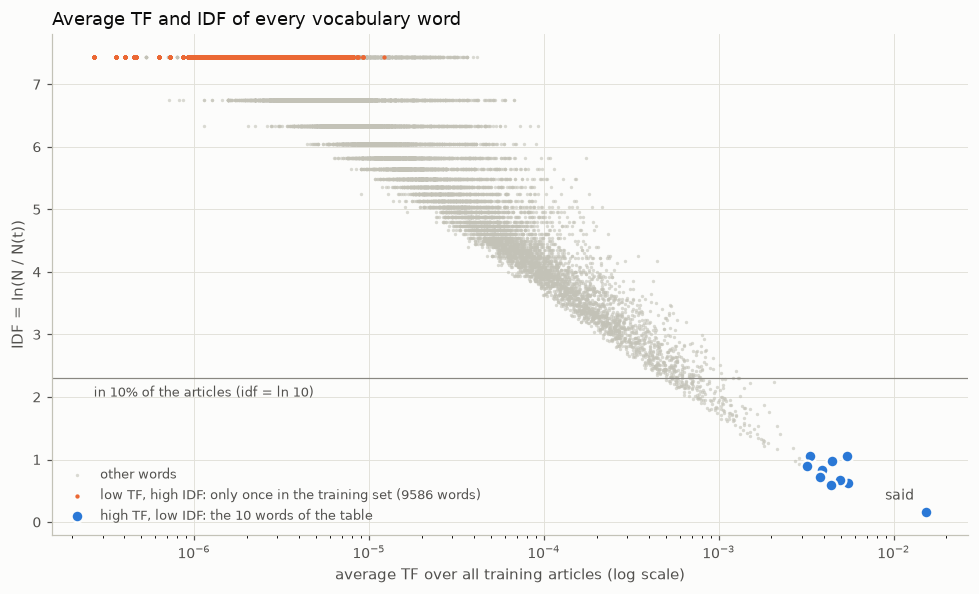

In [20]:
SURFACE, GRID, AXIS, INK, MUTED = "#fcfcfb", "#e1e0d9", "#c3c2b7", "#52514e", "#898781"
BLUE, ORANGE = "#2a78d6", "#eb6834"

highlight = set(high_tf_low_idf["word"]) | set(rare["word"])
others = word_stats[~word_stats["word"].isin(highlight)]

fig, ax = plt.subplots(figsize=(9, 5.5), dpi=110)
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)

ax.scatter(others["avg_tf"], others["idf"], s=5, color=AXIS, alpha=0.6, linewidths=0, label="other words")
ax.scatter(rare["avg_tf"], rare["idf"], s=8, color=ORANGE, linewidths=0,
           label=f"low TF, high IDF: only once in the training set ({len(rare)} words)")
ax.scatter(high_tf_low_idf["avg_tf"], high_tf_low_idf["idf"], s=60, color=BLUE, edgecolors=SURFACE,
           linewidths=1.5, zorder=3, label="high TF, low IDF: the 10 words of the table")

ax.axhline(math.log(10), color=MUTED, linewidth=0.8, zorder=1)
ax.text(word_stats["avg_tf"].min(), math.log(10) - 0.12, "in 10% of the articles (idf = ln 10)",
        color=INK, fontsize=8.5, va="top")
said = word_stats[word_stats["word"] == "said"].iloc[0]
ax.annotate("said", (said["avg_tf"], said["idf"]), xytext=(-8, 8), textcoords="offset points",
            ha="right", color=INK, fontsize=9)

ax.set_xscale("log")
ax.set_xlabel("average TF over all training articles (log scale)", color=INK)
ax.set_ylabel("IDF = ln(N / N(t))", color=INK)
ax.set_title("Average TF and IDF of every vocabulary word", color="#0b0b0b", loc="left")
ax.grid(color=GRID, linewidth=0.6)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_color(AXIS)
ax.tick_params(colors=INK, labelsize=9)
legend = ax.legend(loc="lower left", fontsize=8.5, frameon=False, labelcolor=INK)
plt.tight_layout()
plt.show()

## 7. Classification with cosine similarity

The objective of the task is to classify the articles, so I use my BoW and TF-IDF vectors for that. The lecture
shows the idea: turn the new document into a vector with the same vocabulary and compare it with known documents
using cosine similarity. I tried two simple versions:

* **nearest document:** the test article gets the category of the most similar training article (this is the
  "closest document" idea from the lecture);
* **nearest category centroid:** for every category I average the (length-normalized) vectors of its training
  articles. The test article gets the category whose average vector is the most similar.

All vectors are first divided by their length (L2 norm), then cosine similarity is just the dot product.

In [21]:
def l2_normalize(vector):
    length = vector_length(vector)
    if length == 0:
        return {}
    return {index: value / length for index, value in vector.items()}


def predict_nearest_document(vector, train_vectors, train_labels):
    best_score, best_label = -1.0, None
    for train_vector, label in zip(train_vectors, train_labels):
        score = dot(vector, train_vector)        # = cosine similarity, the vectors have length 1
        if score > best_score:
            best_score, best_label = score, label
    return best_label


def category_centroids(train_vectors, train_labels):
    sums = defaultdict(lambda: defaultdict(float))
    counts = Counter(train_labels)
    for vector, label in zip(train_vectors, train_labels):
        for index, value in vector.items():
            sums[label][index] += value
    return {label: l2_normalize({i: v / counts[label] for i, v in sums[label].items()}) for label in sums}


def predict_nearest_centroid(vector, centroids):
    return max(centroids, key=lambda label: dot(vector, centroids[label]))


def accuracy(predicted, true):
    return sum(p == t for p, t in zip(predicted, true)) / len(true)

In [22]:
results = {}
predictions = {}
for name, train_vectors, test_vectors in [("Bag of Words", bow_train, bow_test),
                                          ("TF-IDF", tfidf_train, tfidf_test)]:
    train_n = [l2_normalize(v) for v in train_vectors]
    test_n = [l2_normalize(v) for v in test_vectors]

    start = time.time()
    pred_doc = [predict_nearest_document(v, train_n, train_labels) for v in test_n]
    seconds = time.time() - start

    centroids = category_centroids(train_n, train_labels)
    pred_centroid = [predict_nearest_centroid(v, centroids) for v in test_n]

    predictions[name] = {"nearest document": pred_doc, "nearest centroid": pred_centroid}
    results[name] = {"nearest document": accuracy(pred_doc, test_labels),
                     "nearest centroid": accuracy(pred_centroid, test_labels)}
    print(f"{name}: done (nearest document search took {seconds:.0f} s)")

print()
print(f"Test accuracy on {len(test_labels)} test articles:")
(pd.DataFrame(results).T * 100).round(1)

Bag of Words: done (nearest document search took 10 s)


TF-IDF: done (nearest document search took 11 s)

Test accuracy on 426 test articles:


,nearest document,nearest centroid
Bag of Words,92.5,92.3
TF-IDF,90.8,97.2


In [23]:
# Confusion matrix of the best combination: TF-IDF + nearest centroid
best = predictions["TF-IDF"]["nearest centroid"]
pd.crosstab(pd.Series(test_labels, name="true category"), pd.Series(best, name="predicted category"))

predicted category,business,entertainment,politics,sport,tech
true category,,,,,
business,93,1,2,0,5
entertainment,0,72,2,0,0
politics,1,0,80,0,0
sport,0,0,0,101,0
tech,0,0,0,1,68


In [24]:
# Accuracy per category for the 4 combinations
per_category = {}
for name in predictions:
    for method, pred in predictions[name].items():
        per_category[f"{name}, {method}"] = {
            category: 100 * sum(p == t for p, t in zip(pred, test_labels) if t == category)
                      / test_labels.count(category)
            for category in categories}
pd.DataFrame(per_category).round(1)

,"Bag of Words, nearest document","Bag of Words, nearest centroid","TF-IDF, nearest document","TF-IDF, nearest centroid"
business,86.1,88.1,83.2,92.1
entertainment,89.2,86.5,93.2,97.3
politics,95.1,95.1,95.1,98.8
sport,99.0,97.0,96.0,100.0
tech,92.8,94.2,87.0,98.6


* The best result is **TF-IDF + nearest centroid with 97.2%** accuracy (12 of the 426 test articles are wrong).
  Sport is perfect; most mistakes are business articles predicted as tech (5), which makes sense, because articles
  about technology companies are business and tech news at the same time.
* With nearest centroid, TF-IDF is clearly better than BoW (97.2% vs 92.3%). With raw counts the frequent general
  words (`said`, `year`, `also`) have a big influence on the cosine similarity; TF-IDF gives them a small weight, so
  the topic words decide.
* With nearest document, TF-IDF (90.8%) was a bit worse than BoW (92.5%). My explanation: with TF-IDF, rare words
  like names get very high weights, so two articles can look similar only because they share one rare name, and
  with only one neighbour such a mistake directly decides the category. A centroid is the average of hundreds of
  articles, so single rare words lose their influence and the typical words of the category remain.
* Nearest centroid is also much faster: 5 comparisons per test article instead of 1700.

## Summary

* **Data:** 2225 articles; 99 exact duplicates removed, so 2126 articles remain. Split 80/20 inside every category
  (1700 training, 426 test articles, seed 36111).
* **Preprocessing:** lower case, punctuation removed, tokenized, NLTK stop words removed (and tokens that are only
  numbers). An average article went from 390.5 to 219.2 words.
* **Bag of Words:** my own vocabulary from the training set (V = 25971 words) and sparse count vectors, checked
  against the lecture example.
* **TF-IDF:** normalized TF times `ln(N / N(t))`, IDF from the training set, checked against the lecture example
  (the same IDF values and cosine similarities).
* **Analysis:** the top TF-IDF words describe each category well. Words like `said`, `also` and `one` have high TF
  but low IDF, and TF-IDF lowers their importance; words that appear only once have the highest IDF but almost no TF.
* **Classification:** TF-IDF vectors with a nearest-centroid classifier (cosine similarity) reach 97.2% test accuracy.